# Pseudo-Label Generation

Prerequisites: Run Grounding DINO Inference on COCO training data under inference/

Install the Soft Teacher Repository as we will rely on their defined data splits and use their evaluation pipeline.


What this notebook does:

We generate the Grounding DINO pseudo-label baseline for semi-supervised object detection on COCO.
The labeled subset of images is used to calibrate Grounding DINO confidences post hoc; calibrated predictions above a confidence of 0.5 are then used as pseudo-labels for the remaining images.

# 1 Load Label Information

In [1]:
# Sweep configuration: label budget (% labeled) and data fold
BUDGETS = [1, 5, 10]      # % labeled
FOLDS   = [1, 2, 3, 4, 5]

# combination used by the single-run walkthrough below (Sections 1-3);
# the final sweep section iterates over every combination in BUDGETS x FOLDS
perc_labeled = BUDGETS[0]
fold = FOLDS[0]

In [2]:
import os

st_dir = "/home/klees/SoftTeacher/" # Soft Teacher Repository


labels_json = os.path.join(st_dir, f"data/coco/annotations/semi_supervised/instances_train2017.{fold}@{perc_labeled}.json")

In [3]:
import json
with open(labels_json, "r") as f:
    labels = json.load(f)

# 2 Post-Hoc Calibration of Grounding DINO Predictions

Here, we calibrate model confidence using a regression model and the provided labels as targets. 
I.e., a TP detection has target 1.0 for the confidence and a FP detection 0.0.

We use Isotonic Regression or Logistic Regression (Platt Scaling) where Isotonic Regression leads to better calibration in terms of ECE.

In [4]:
import sys

# notebook lives in a subfolder; add the repo root to sys.path so that
# calibration/ and inference/ are reachable with their original import paths
repo_root = os.path.abspath("..")
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

model = "gdino"
dataset = "coco_train"

pred_parquet = os.path.join(repo_root, f"inference/predictions/{model}/{dataset}/predictions.parquet")

In [5]:
import numpy as np
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

In [6]:
from calibration.calibrate import gather_detections_from_parquet, extract_per_image_scores, flatten_per_image_data
import pandas as pd

labeled_image_ids = [img["id"] for img in labels["images"]] # IDs of images for which labels are provided

out_dir = "grounding_dino_pseudo_labels"
os.makedirs(out_dir, exist_ok=True)

save_path = os.path.join(out_dir, f"calibration_inputs_fold{fold}_{perc_labeled}pct.json")

if os.path.exists(save_path):
    print(f"Loading calibration inputs from {save_path}")
    with open(save_path, "r") as f:
        payload = json.load(f)

    scores, TP_mask, det_image_ids = payload["scores"], payload["TP_mask"], payload["image_ids"]

    cocoGt = COCO(labels_json)

else:
    # load detections for labeled images from the parquet file
    all_detections = gather_detections_from_parquet(labeled_image_ids, pred_parquet)

    cocoGt = COCO(labels_json)
    cocoDt = cocoGt.loadRes(all_detections)

    cocoEval = COCOeval(cocoGt, cocoDt, "bbox")
    cocoEval.params.iouThrs = [0.5]
    cocoEval.params.areaRng = [cocoEval.params.areaRng[0]]
    cocoEval.params.maxDets = [300]

    cocoEval.evaluate()
    cocoEval.accumulate()

    per_image_data = extract_per_image_scores(cocoEval)
    scores, TP_mask, det_image_ids = flatten_per_image_data(per_image_data) # one entry per detection

    payload = {
        "scores"  : scores.tolist()   if hasattr(scores,   "tolist") else list(scores),
        "image_ids": det_image_ids.tolist() if hasattr(det_image_ids, "tolist") else list(det_image_ids),
        "TP_mask" : TP_mask.tolist()  if hasattr(TP_mask,  "tolist") else list(TP_mask),
    }

    with open(save_path, "w") as f:
        json.dump(payload, f)

    print(f"Saved scores, image_ids, TP_mask to: {save_path}")

loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
Loading and preparing results...
DONE (t=1.70s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=2.96s).
Accumulating evaluation results...
DONE (t=0.13s).
Saved scores, image_ids, TP_mask to: grounding_dino_pseudo_labels/calibration_inputs_fold1_1pct.json


In [7]:
print(f"Total detections: {len(scores)}, Total TPs: {sum(TP_mask)}, Total FPs: {len(TP_mask) - sum(TP_mask)}")

number_of_labels = len(cocoGt.anns)

print(f"Number of labeled instances: {number_of_labels}, Number of labeled images: {len(labeled_image_ids)}")

Total detections: 354600, Total TPs: 8254, Total FPs: 346346
Number of labeled instances: 8646, Number of labeled images: 1182


In [8]:
# Post-hoc calibration: Platt scaling and isotonic regression (the latter is used below)

###########################
# 1. Platt Scaling (Logistic Regression)
log_reg = LogisticRegression()
log_reg.fit(np.array(scores).reshape(-1,1), TP_mask) # fit to training data: predictions evaluated against provided GT examples

###########################
# 2. Isotonic Regression

ir = IsotonicRegression(out_of_bounds='clip')  # clip scores outside training range
ir.fit(np.array(scores).reshape(-1,1), TP_mask)

,y_min,None
,y_max,None
,increasing,True
,out_of_bounds,'clip'


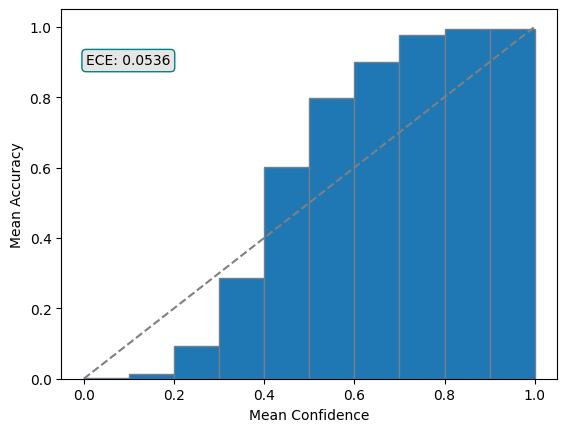

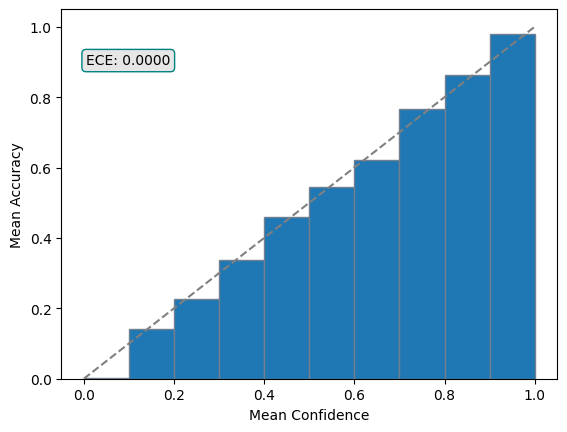

In [9]:
from calibration.calibrate import plot_reliability_diagram

scores_arr = np.array(scores)
TP_mask_arr = np.array(TP_mask)

# Before calibration
plot_reliability_diagram(scores_arr, TP_mask_arr)

# After calibration (Isotonic Regression)
cal_scores = ir.predict(scores_arr)
plot_reliability_diagram(cal_scores, TP_mask_arr)

At threshold 0.5:
  Kept:      6,462 / 354,600 detections
  Precision: 0.8386
  Recall:    0.6565
  F1:        0.7365


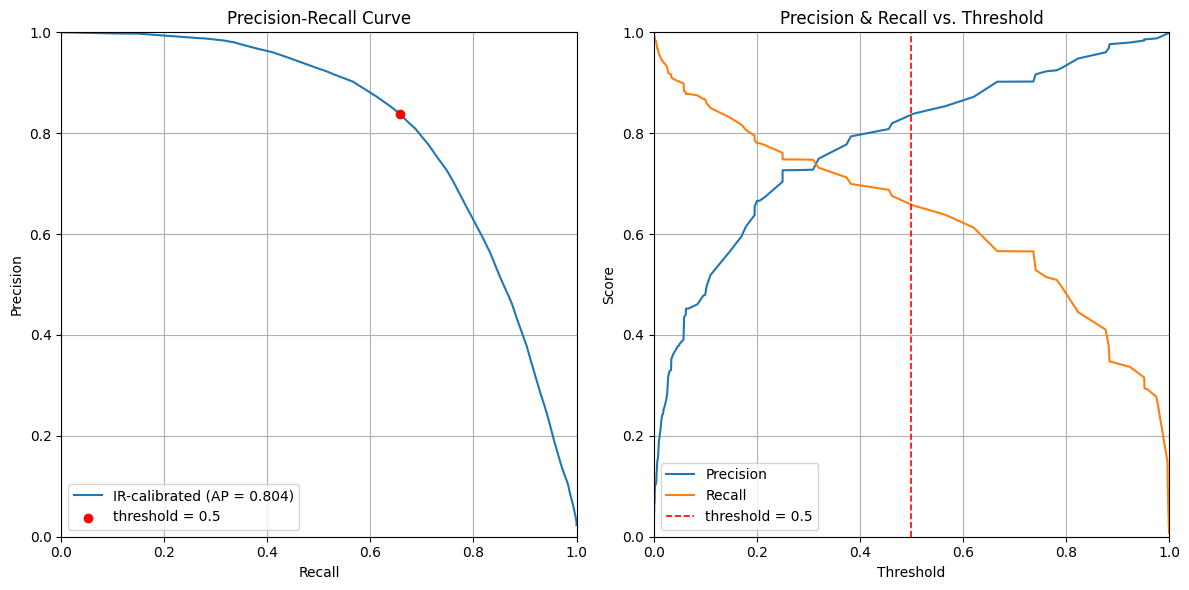

In [10]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
# --- Evaluate at threshold = 0.5 ---
threshold = 0.5
predicted_positive = cal_scores >= threshold

TP = np.sum(predicted_positive & (TP_mask_arr == 1))
FP = np.sum(predicted_positive & (TP_mask_arr == 0))
FN = np.sum(~predicted_positive & (TP_mask_arr == 1))

precision_at_t = TP / (TP + FP) if (TP + FP) > 0 else 0.0
recall_at_t    = TP / (TP + FN) if (TP + FN) > 0 else 0.0
f1_at_t        = 2 * precision_at_t * recall_at_t / (precision_at_t + recall_at_t) if (precision_at_t + recall_at_t) > 0 else 0.0

print(f"At threshold {threshold}:")
print(f"  Kept:      {int(predicted_positive.sum()):,} / {len(cal_scores):,} detections")
print(f"  Precision: {precision_at_t:.4f}")
print(f"  Recall:    {recall_at_t:.4f}")
print(f"  F1:        {f1_at_t:.4f}")

# --- Precision-Recall curve (sweep threshold) ---
precisions, recalls, thresholds_pr = precision_recall_curve(TP_mask_arr, cal_scores)
ap = average_precision_score(TP_mask_arr, cal_scores)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Plot 1: PR curve (Recall vs Precision)
axes[0].plot(recalls, precisions, lw=1.5, label=f"IR-calibrated (AP = {ap:.3f})")
axes[0].scatter([recall_at_t], [precision_at_t], color="red", zorder=5,
                label=f"threshold = {threshold}")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-Recall Curve")
axes[0].legend()
axes[0].grid(True)

# Plot 2: Precision & Recall vs Threshold
# precision_recall_curve returns one extra point (precision=1, recall=0) without a threshold
axes[1].plot(thresholds_pr, precisions[:-1], lw=1.5, label="Precision")
axes[1].plot(thresholds_pr, recalls[:-1],    lw=1.5, label="Recall")
axes[1].axvline(x=threshold, color="red", linestyle="--", lw=1.2, label=f"threshold = {threshold}")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("Score")
axes[1].set_title("Precision & Recall vs. Threshold")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [11]:
from tqdm.auto import tqdm

# ── NMS + TP-matching helpers ─────────────────────────────────────────────────

def _iou_matrix(b1, b2):
    """(N,4)×(M,4) → (N,M) IoU; boxes as [x1,y1,x2,y2]."""
    if len(b1) == 0 or len(b2) == 0:
        return np.zeros((len(b1), len(b2)))
    x1 = np.maximum(b1[:, None, 0], b2[None, :, 0])
    y1 = np.maximum(b1[:, None, 1], b2[None, :, 1])
    x2 = np.minimum(b1[:, None, 2], b2[None, :, 2])
    y2 = np.minimum(b1[:, None, 3], b2[None, :, 3])
    inter  = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
    areas1 = (b1[:, 2] - b1[:, 0]) * (b1[:, 3] - b1[:, 1])
    areas2 = (b2[:, 2] - b2[:, 0]) * (b2[:, 3] - b2[:, 1])
    return inter / np.maximum(areas1[:, None] + areas2[None, :] - inter, 1e-6)

def _nms(boxes, scores, cat_ids, iou_thr, class_agnostic):
    """Boolean survive mask after NMS (per-class or class-agnostic)."""
    survive = np.zeros(len(boxes), dtype=bool)
    groups  = [None] if class_agnostic else np.unique(cat_ids)
    for g in groups:
        idx   = np.arange(len(boxes)) if g is None else np.where(cat_ids == g)[0]
        if len(idx) == 0:
            continue
        order   = np.argsort(scores[idx])[::-1]
        b_ord   = boxes[idx][order]
        iou_mat = _iou_matrix(b_ord, b_ord)
        sup     = np.zeros(len(idx), dtype=bool)
        for i in range(len(idx)):
            if sup[i]:
                continue
            survive[idx[order[i]]] = True
            sup[i + 1:] |= iou_mat[i, i + 1:] > iou_thr
    return survive

def _tp_mask(boxes, scores, cat_ids, gt_anns, iou_thr=0.5):
    """Greedy (score-descending) TP assignment vs GT annotations."""
    tp = np.zeros(len(boxes), dtype=np.int8)
    if not gt_anns or len(boxes) == 0:
        return tp
    gt_b  = np.array([[a["bbox"][0], a["bbox"][1],
                        a["bbox"][0] + a["bbox"][2],
                        a["bbox"][1] + a["bbox"][3]] for a in gt_anns])
    gt_c  = np.array([a["category_id"] for a in gt_anns])
    used  = np.zeros(len(gt_anns), dtype=bool)
    ious  = _iou_matrix(boxes, gt_b)
    for i in np.argsort(scores)[::-1]:
        same = (gt_c == cat_ids[i]) & ~used
        if not same.any():
            continue
        row  = ious[i] * same
        best = row.argmax()
        if row[best] >= iou_thr:
            tp[i]      = 1
            used[best] = True
    return tp

# ── Process all labeled images ────────────────────────────────────────────────

iou_nms     = 0.5
unique_imgs = sorted(set(int(i) for i in det_image_ids))

# Read predictions for labeled images from parquet in one shot
df_pred    = pd.read_parquet(pred_parquet, columns=["image_id", "score", "label", "box"])
df_labeled = df_pred[df_pred["image_id"].isin(set(unique_imgs))]

sc_l, tp_l, pc_l, ag_l = [], [], [], []

for img_id, grp in tqdm(df_labeled.groupby("image_id"), desc="NMS analysis"):
    if grp.empty:
        continue
    boxes = np.array(grp["box"].tolist(),    dtype=np.float32)  # [x1,y1,x2,y2]
    scr   = grp["score"].values.astype(np.float32)
    cats  = grp["label"].values.astype(np.int32)

    sc_l.append(scr)
    tp_l.append(_tp_mask(boxes, scr, cats, cocoGt.imgToAnns.get(img_id, [])))
    pc_l.append(_nms(boxes, scr, cats, iou_nms, class_agnostic=False))
    ag_l.append(_nms(boxes, scr, cats, iou_nms, class_agnostic=True))

r_scores = np.concatenate(sc_l)
r_tp     = np.concatenate(tp_l).astype(int)
r_nms_pc = np.concatenate(pc_l)
r_nms_ag = np.concatenate(ag_l)

# ── Duplicate rate summary ────────────────────────────────────────────────────

total    = len(r_scores)
total_gt = sum(len(cocoGt.imgToAnns.get(i, [])) for i in unique_imgs)

print(f"Total detections : {total:,}")
print(f"Total GT objects : {total_gt:,}")
print(f"Raw recall ceiling : {r_tp.sum()/total_gt:.3f}  ({r_tp.sum():,} GT matched at any score)\n")

for name, mask in [("Per-class NMS", r_nms_pc), ("Class-agnostic NMS", r_nms_ag)]:
    sup     = int((~mask).sum())
    sup_tp  = int((~mask & (r_tp == 1)).sum())
    surv_tp = int(( mask & (r_tp == 1)).sum())
    print(f"{name} (IoU ≥ {iou_nms}):")
    print(f"  Duplicate rate  : {sup/total:.1%}  ({sup:,} suppressed)")
    print(f"  Suppressed TPs  : {sup_tp:,}  ({sup_tp/max(sup,1):.1%} of suppressed, "
          f"{sup_tp/max(r_tp.sum(),1):.1%} of all TPs)")
    print(f"  Recall ceiling  : {surv_tp/total_gt:.3f}\n")

/home/klees/miniconda3/envs/open_vocabs/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
NMS analysis: 100%|██████████| 1182/1182 [00:03<00:00, 340.18it/s]

Total detections : 354,600
Total GT objects : 8,646
Raw recall ceiling : 0.958  (8,286 GT matched at any score)

Per-class NMS (IoU ≥ 0.5):
  Duplicate rate  : 35.5%  (125,756 suppressed)
  Suppressed TPs  : 252  (0.2% of suppressed, 3.0% of all TPs)
  Recall ceiling  : 0.929

Class-agnostic NMS (IoU ≥ 0.5):
  Duplicate rate  : 64.0%  (226,983 suppressed)
  Suppressed TPs  : 625  (0.3% of suppressed, 7.5% of all TPs)
  Recall ceiling  : 0.886



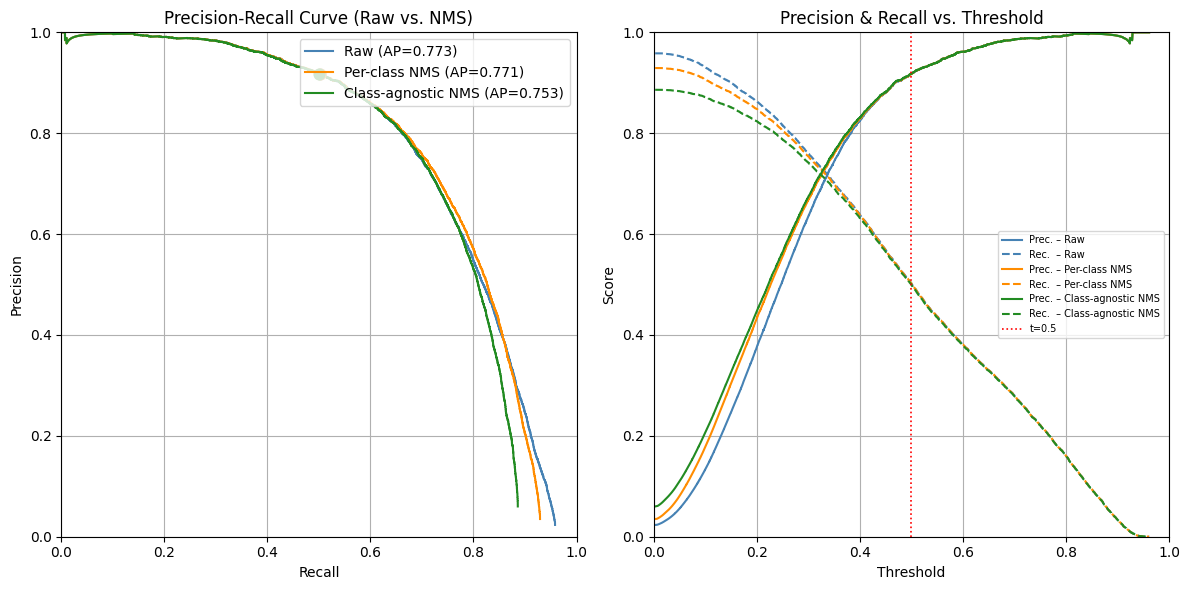

In [12]:
from sklearn.metrics import precision_recall_curve

threshold  = 0.5
conditions = [
    (np.ones(len(r_scores), dtype=bool), "Raw",                "steelblue"),
    (r_nms_pc,                            "Per-class NMS",      "darkorange"),
    (r_nms_ag,                            "Class-agnostic NMS", "forestgreen"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for cond, label, color in conditions:
    s = r_scores[cond]
    t = r_tp[cond]

    prec, rec, thr = precision_recall_curve(t, s)
    rec_sc = rec * t.sum() / total_gt          # rescale recall to total GT objects
    ap     = np.trapz(prec[::-1], rec_sc[::-1])

    above = cond & (r_scores >= threshold)
    tp_t  = int((above & (r_tp == 1)).sum())
    fp_t  = int((above & (r_tp == 0)).sum())
    p_t   = tp_t / (tp_t + fp_t) if (tp_t + fp_t) > 0 else 0.0
    r_t   = tp_t / total_gt

    # Left: PR curve
    axes[0].plot(rec_sc, prec, lw=1.5, color=color, label=f"{label} (AP={ap:.3f})")
    axes[0].scatter([r_t], [p_t], color=color, zorder=5, s=60)

    # Right: precision & recall vs threshold
    axes[1].plot(thr, prec[:-1],   lw=1.5, ls="-",  color=color, label=f"Prec. – {label}")
    axes[1].plot(thr, rec_sc[:-1], lw=1.5, ls="--", color=color, label=f"Rec.  – {label}")

axes[1].axvline(x=threshold, color="red", ls=":", lw=1.2, label=f"t={threshold}")

for ax in axes:
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(True)

axes[0].set_xlabel("Recall");    axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-Recall Curve (Raw vs. NMS)")
axes[0].legend(loc="upper right")

axes[1].set_xlabel("Threshold"); axes[1].set_ylabel("Score")
axes[1].set_title("Precision & Recall vs. Threshold")
axes[1].legend(loc="center right", fontsize=7)

plt.tight_layout()
plt.show()

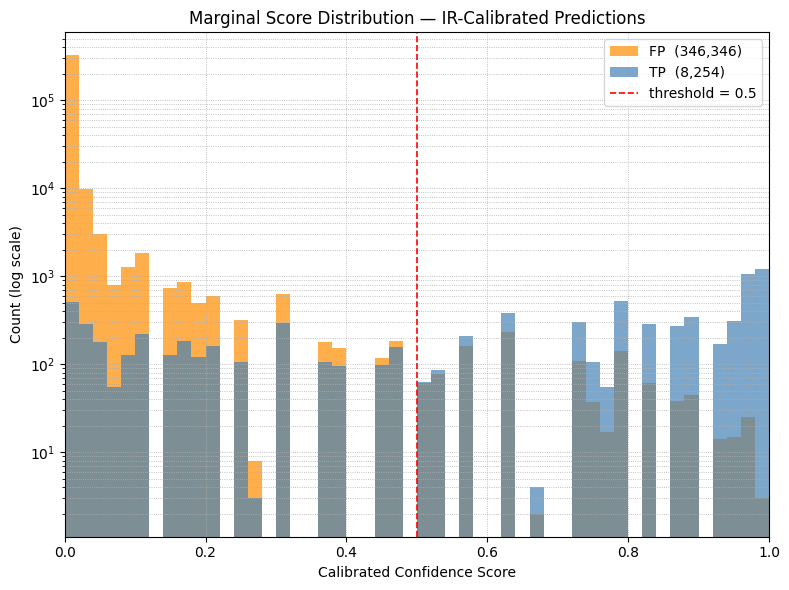

In [13]:
import matplotlib.pyplot as plt

bins = np.linspace(0, 1, 51)   # 50 equal-width bins over [0, 1]

fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(cal_scores[TP_mask_arr == 0], bins=bins, alpha=0.7,
        color="darkorange", label=f"FP  ({(TP_mask_arr == 0).sum():,})")
ax.hist(cal_scores[TP_mask_arr == 1], bins=bins, alpha=0.7,
        color="steelblue",  label=f"TP  ({(TP_mask_arr == 1).sum():,})")

ax.axvline(x=0.5, color="red", ls="--", lw=1.2, label="threshold = 0.5")

ax.set_yscale("log")
ax.set_xlim(0, 1)
ax.set_xlabel("Calibrated Confidence Score")
ax.set_ylabel("Count (log scale)")
ax.set_title("Marginal Score Distribution — IR-Calibrated Predictions")
ax.legend()
ax.grid(True, which="both", ls=":", lw=0.6)
plt.tight_layout()
plt.show()

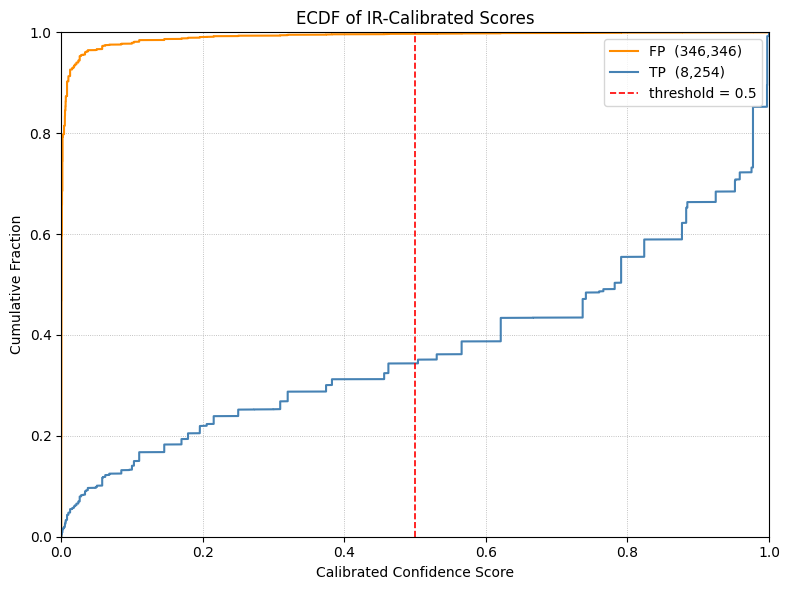

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))

for mask, label, color in [
    (TP_mask_arr == 0, f"FP  ({(TP_mask_arr == 0).sum():,})", "darkorange"),
    (TP_mask_arr == 1, f"TP  ({(TP_mask_arr == 1).sum():,})", "steelblue"),
]:
    x = np.sort(cal_scores[mask])
    y = np.arange(1, len(x) + 1) / len(x)
    ax.plot(x, y, lw=1.5, label=label, color=color)

ax.axvline(x=0.5, color="red", ls="--", lw=1.2, label="threshold = 0.5")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Calibrated Confidence Score")
ax.set_ylabel("Cumulative Fraction")
ax.set_title("ECDF of IR-Calibrated Scores")
ax.legend()
ax.grid(True, ls=":", lw=0.6)
plt.tight_layout()
plt.show()

# 3 Baseline: Use GD Predictions directly.

Here, we use the provided labels for post-hoc calibration and set a threshold of 0.5 to include only sufficiently confident predictions as pseudo-labels.
For the labeled images, we keep the provided annotations and combine them with the Grounding DINO pseudo-labels for all remaining training images (e.g., 1% labeled and 99% pseudo-labeled images for the budget used here).

We store the labels into the Soft Teacher Repository for subsequent evaluation. 

In [15]:
# ── Construct pseudo-label training data in COCO format ───────────────────────
#
# Final dataset combines:
#   - GT annotations  for the labeled images  (taken from cocoGt)
#   - Pseudo-labels   for all unlabeled images
#     derived via: per-class NMS  →  IR calibration  →  confidence ≥ 0.5

IOU_NMS   = 0.5   # NMS IoU threshold
SCORE_THR = 0.5   # post-calibration confidence cut-off

out_path = os.path.join(out_dir, f"pseudo_labels_fold{fold}_{perc_labeled}pct.json")

if os.path.exists(out_path):
    print(f"Loading pseudo-labels from {out_path}")
    with open(out_path, "r") as f:
        coco_out = json.load(f)
    print(f"  Total images      : {len(coco_out['images']):,}")
    print(f"  Total annotations : {len(coco_out['annotations']):,}")

else:
    labeled_img_ids = set(cocoGt.imgs.keys())

    # unlabeled images = all images with predictions that are not in the labeled split
    df_all      = pd.read_parquet(pred_parquet, columns=["image_id", "score", "label", "box"])
    unlabeled_ids = sorted(
        int(i) for i in df_all["image_id"].unique() if int(i) not in labeled_img_ids
    )
    df_unlabeled = df_all[df_all["image_id"].isin(set(unlabeled_ids))]

    print(f"Labeled images   : {len(labeled_img_ids):,}")
    print(f"Unlabeled images : {len(unlabeled_ids):,}")

    # Load full COCO train annotations for image metadata (height, width, file_name …)
    full_train_ann = os.path.join(st_dir, "data/coco/annotations/instances_train2017.json")
    if os.path.exists(full_train_ann):
        with open(full_train_ann) as f:
            _full = json.load(f)
        full_img_info = {img["id"]: img for img in _full["images"]}
        categories    = _full["categories"]
        print("Loaded full train annotations for image metadata.")
    else:
        full_img_info = dict(cocoGt.imgs)
        categories    = list(cocoGt.cats.values())
        print("Warning: instances_train2017.json not found — "
              "image metadata limited to the labeled split.")

    # ── Generate pseudo-labels for unlabeled images ────────────────────────────

    next_ann_id        = max(cocoGt.anns.keys(), default=0) + 1
    pseudo_images      = []
    pseudo_annotations = []

    for img_id, grp in tqdm(df_unlabeled.groupby("image_id"), desc="Pseudo-labels"):
        boxes = np.array(grp["box"].tolist(),  dtype=np.float32)  # [x1,y1,x2,y2]
        scr   = grp["score"].values.astype(np.float32)
        cats  = grp["label"].values.astype(np.int32)

        # Step 1 — per-class NMS
        survive = _nms(boxes, scr, cats, IOU_NMS, class_agnostic=False)
        boxes, scr, cats = boxes[survive], scr[survive], cats[survive]
        if len(boxes) == 0:
            continue

        # Step 2 — IR calibration
        cal_scr = ir.predict(scr)

        # Step 3 — confidence filter
        keep = cal_scr >= SCORE_THR
        boxes, cal_scr, cats = boxes[keep], cal_scr[keep], cats[keep]
        if len(boxes) == 0:
            continue

        if img_id in full_img_info:
            pseudo_images.append(full_img_info[img_id])

        for box, conf, cat_id in zip(boxes, cal_scr, cats):
            x1, y1, x2, y2 = map(float, box)
            w, h = x2 - x1, y2 - y1
            pseudo_annotations.append({
                "id"          : next_ann_id,
                "image_id"    : int(img_id),
                "category_id" : int(cat_id),
                "bbox"        : [x1, y1, w, h],
                "area"        : w * h,
                "score"       : float(conf),
                "iscrowd"     : 0,
                "segmentation": [],
            })
            next_ann_id += 1

    # ── Assemble and save final COCO JSON ─────────────────────────────────────

    labeled_images      = list(cocoGt.imgs.values())
    labeled_annotations = list(cocoGt.anns.values())

    coco_out = {
        "images"     : labeled_images + pseudo_images,
        "annotations": labeled_annotations + pseudo_annotations,
        "categories" : categories,
    }

    with open(out_path, "w") as f:
        json.dump(coco_out, f)

    print(f"\nSaved: {out_path}")
    print(f"  Total images      : {len(coco_out['images']):,}  "
          f"({len(labeled_images):,} labeled + {len(pseudo_images):,} unlabeled)")
    print(f"  Total annotations : {len(coco_out['annotations']):,}  "
          f"({len(labeled_annotations):,} GT + {len(pseudo_annotations):,} pseudo-labels)")

Labeled images   : 1,182
Unlabeled images : 117,105
Loaded full train annotations for image metadata.


Pseudo-labels: 100%|██████████| 117105/117105 [02:37<00:00, 741.35it/s]



Saved: grounding_dino_pseudo_labels/pseudo_labels_fold1_1pct.json
  Total images      : 116,572  (1,182 labeled + 115,390 unlabeled)
  Total annotations : 645,991  (8,646 GT + 637,345 pseudo-labels)


## Sweep over all budgets and folds

Runs the calibration + pseudo-label pipeline above for every `(budget, fold)` combination in `BUDGETS x FOLDS`, saving a `pseudo_labels_fold{fold}_{perc_labeled}pct.json` (plus its supporting `calibration_inputs_fold{fold}_{perc_labeled}pct.json` cache) per combination. Combinations whose output already exists on disk are skipped.

In [16]:
def generate_pseudo_labels(perc_labeled, fold):
    """Run the calibration + pseudo-label pipeline for one (budget, fold) combo."""

    out_path_ = os.path.join(out_dir, f"pseudo_labels_fold{fold}_{perc_labeled}pct.json")
    if os.path.exists(out_path_):
        print(f"[{perc_labeled}% / fold {fold}] Already exists: {out_path_}")
        return out_path_

    # ── labeled-subset ground truth ────────────────────────────────────────
    labels_json_ = os.path.join(
        st_dir, f"data/coco/annotations/semi_supervised/instances_train2017.{fold}@{perc_labeled}.json"
    )
    with open(labels_json_, "r") as f:
        labels_ = json.load(f)
    image_ids_ = [img["id"] for img in labels_["images"]]

    # ── calibration inputs (scores / TP mask), cached per combo ───────────
    cal_path_ = os.path.join(out_dir, f"calibration_inputs_fold{fold}_{perc_labeled}pct.json")
    if os.path.exists(cal_path_):
        with open(cal_path_, "r") as f:
            payload = json.load(f)
        scores_, TP_mask_ = payload["scores"], payload["TP_mask"]
        cocoGt_ = COCO(labels_json_)
    else:
        all_detections = gather_detections_from_parquet(image_ids_, pred_parquet)

        cocoGt_ = COCO(labels_json_)
        cocoDt_ = cocoGt_.loadRes(all_detections)

        cocoEval_ = COCOeval(cocoGt_, cocoDt_, "bbox")
        cocoEval_.params.iouThrs = [0.5]
        cocoEval_.params.areaRng = [cocoEval_.params.areaRng[0]]
        cocoEval_.params.maxDets = [300]

        cocoEval_.evaluate()
        cocoEval_.accumulate()

        per_image_data = extract_per_image_scores(cocoEval_)
        scores_, TP_mask_, _ = flatten_per_image_data(per_image_data)

        payload = {
            "scores"   : scores_.tolist()   if hasattr(scores_,   "tolist") else list(scores_),
            "image_ids": image_ids_,
            "TP_mask"  : TP_mask_.tolist()  if hasattr(TP_mask_,  "tolist") else list(TP_mask_),
        }
        with open(cal_path_, "w") as f:
            json.dump(payload, f)

    # ── fit isotonic-regression calibrator for this combo ─────────────────
    ir_ = IsotonicRegression(out_of_bounds="clip")
    ir_.fit(np.array(scores_).reshape(-1, 1), TP_mask_)

    # ── build + save combined (GT + pseudo-labeled) COCO training set ─────
    labeled_img_ids = set(cocoGt_.imgs.keys())

    df_all = pd.read_parquet(pred_parquet, columns=["image_id", "score", "label", "box"])
    unlabeled_ids = sorted(int(i) for i in df_all["image_id"].unique() if int(i) not in labeled_img_ids)
    df_unlabeled = df_all[df_all["image_id"].isin(set(unlabeled_ids))]

    full_train_ann = os.path.join(st_dir, "data/coco/annotations/instances_train2017.json")
    if os.path.exists(full_train_ann):
        with open(full_train_ann) as f:
            _full = json.load(f)
        full_img_info = {img["id"]: img for img in _full["images"]}
        categories = _full["categories"]
    else:
        full_img_info = dict(cocoGt_.imgs)
        categories = list(cocoGt_.cats.values())

    next_ann_id = max(cocoGt_.anns.keys(), default=0) + 1
    pseudo_images, pseudo_annotations = [], []

    for img_id, grp in tqdm(df_unlabeled.groupby("image_id"),
                             desc=f"Pseudo-labels [{perc_labeled}% / fold {fold}]"):
        boxes = np.array(grp["box"].tolist(), dtype=np.float32)  # [x1,y1,x2,y2]
        scr   = grp["score"].values.astype(np.float32)
        cats  = grp["label"].values.astype(np.int32)

        # Step 1 — per-class NMS
        survive = _nms(boxes, scr, cats, IOU_NMS, class_agnostic=False)
        boxes, scr, cats = boxes[survive], scr[survive], cats[survive]
        if len(boxes) == 0:
            continue

        # Step 2 — IR calibration
        cal_scr = ir_.predict(scr)

        # Step 3 — confidence filter
        keep = cal_scr >= SCORE_THR
        boxes, cal_scr, cats = boxes[keep], cal_scr[keep], cats[keep]
        if len(boxes) == 0:
            continue

        if img_id in full_img_info:
            pseudo_images.append(full_img_info[img_id])

        for box, conf, cat_id in zip(boxes, cal_scr, cats):
            x1, y1, x2, y2 = map(float, box)
            w, h = x2 - x1, y2 - y1
            pseudo_annotations.append({
                "id"          : next_ann_id,
                "image_id"    : int(img_id),
                "category_id" : int(cat_id),
                "bbox"        : [x1, y1, w, h],
                "area"        : w * h,
                "score"       : float(conf),
                "iscrowd"     : 0,
                "segmentation": [],
            })
            next_ann_id += 1

    labeled_images      = list(cocoGt_.imgs.values())
    labeled_annotations = list(cocoGt_.anns.values())

    coco_out_ = {
        "images"     : labeled_images + pseudo_images,
        "annotations": labeled_annotations + pseudo_annotations,
        "categories" : categories,
    }

    with open(out_path_, "w") as f:
        json.dump(coco_out_, f)

    print(f"[{perc_labeled}% / fold {fold}] Saved: {out_path_}  "
          f"({len(coco_out_['images']):,} images, {len(coco_out_['annotations']):,} annotations)")
    return out_path_

In [17]:
import itertools

for perc_labeled, fold in itertools.product(BUDGETS, FOLDS):
    generate_pseudo_labels(perc_labeled, fold)

[1% / fold 1] Already exists: grounding_dino_pseudo_labels/pseudo_labels_fold1_1pct.json
loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
Loading and preparing results...
DONE (t=3.23s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=2.09s).
Accumulating evaluation results...
DONE (t=0.14s).


Pseudo-labels [1% / fold 2]: 100%|██████████| 117105/117105 [02:34<00:00, 758.14it/s]


[1% / fold 2] Saved: grounding_dino_pseudo_labels/pseudo_labels_fold2_1pct.json  (116,540 images, 640,190 annotations)
loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
Loading and preparing results...
DONE (t=3.73s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=2.15s).
Accumulating evaluation results...
DONE (t=0.16s).


Pseudo-labels [1% / fold 3]: 100%|██████████| 117105/117105 [02:40<00:00, 731.78it/s]


[1% / fold 3] Saved: grounding_dino_pseudo_labels/pseudo_labels_fold3_1pct.json  (116,743 images, 668,852 annotations)
loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.29s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=2.04s).
Accumulating evaluation results...
DONE (t=0.14s).


Pseudo-labels [1% / fold 4]: 100%|██████████| 117105/117105 [02:39<00:00, 733.40it/s]


[1% / fold 4] Saved: grounding_dino_pseudo_labels/pseudo_labels_fold4_1pct.json  (116,466 images, 631,264 annotations)
loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.29s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=1.98s).
Accumulating evaluation results...
DONE (t=0.14s).


Pseudo-labels [1% / fold 5]: 100%|██████████| 117105/117105 [02:36<00:00, 746.25it/s]


[1% / fold 5] Saved: grounding_dino_pseudo_labels/pseudo_labels_fold5_1pct.json  (116,486 images, 634,951 annotations)
loading annotations into memory...
Done (t=0.22s)
creating index...
index created!
Loading and preparing results...
DONE (t=7.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=16.41s).
Accumulating evaluation results...
DONE (t=0.70s).


Pseudo-labels [5% / fold 1]: 100%|██████████| 112373/112373 [02:25<00:00, 774.16it/s]


[5% / fold 1] Saved: grounding_dino_pseudo_labels/pseudo_labels_fold1_5pct.json  (116,644 images, 654,511 annotations)
loading annotations into memory...
Done (t=0.41s)
creating index...
index created!
Loading and preparing results...
DONE (t=7.51s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=17.07s).
Accumulating evaluation results...
DONE (t=0.69s).


Pseudo-labels [5% / fold 2]: 100%|██████████| 112373/112373 [02:39<00:00, 704.60it/s]


[5% / fold 2] Saved: grounding_dino_pseudo_labels/pseudo_labels_fold2_5pct.json  (116,767 images, 670,965 annotations)
loading annotations into memory...
Done (t=0.23s)
creating index...
index created!
Loading and preparing results...
DONE (t=7.81s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=18.63s).
Accumulating evaluation results...
DONE (t=0.72s).


Pseudo-labels [5% / fold 3]: 100%|██████████| 112373/112373 [02:35<00:00, 720.82it/s]


[5% / fold 3] Saved: grounding_dino_pseudo_labels/pseudo_labels_fold3_5pct.json  (116,695 images, 660,819 annotations)
loading annotations into memory...
Done (t=0.23s)
creating index...
index created!
Loading and preparing results...
DONE (t=10.66s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=21.97s).
Accumulating evaluation results...
DONE (t=0.86s).


Pseudo-labels [5% / fold 4]: 100%|██████████| 112373/112373 [02:43<00:00, 687.78it/s]


[5% / fold 4] Saved: grounding_dino_pseudo_labels/pseudo_labels_fold4_5pct.json  (116,663 images, 654,971 annotations)
loading annotations into memory...
Done (t=0.21s)
creating index...
index created!
Loading and preparing results...
DONE (t=7.69s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=12.01s).
Accumulating evaluation results...
DONE (t=0.78s).


Pseudo-labels [5% / fold 5]: 100%|██████████| 112373/112373 [02:36<00:00, 718.12it/s]


[5% / fold 5] Saved: grounding_dino_pseudo_labels/pseudo_labels_fold5_5pct.json  (116,541 images, 642,072 annotations)
loading annotations into memory...
Done (t=0.46s)
creating index...
index created!
Loading and preparing results...
DONE (t=20.51s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=20.97s).
Accumulating evaluation results...
DONE (t=1.51s).


Pseudo-labels [10% / fold 1]: 100%|██████████| 106459/106459 [02:25<00:00, 729.58it/s]


[10% / fold 1] Saved: grounding_dino_pseudo_labels/pseudo_labels_fold1_10pct.json  (116,696 images, 661,013 annotations)
loading annotations into memory...
Done (t=8.00s)
creating index...
index created!
Loading and preparing results...
DONE (t=11.48s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=34.40s).
Accumulating evaluation results...
DONE (t=1.77s).


Pseudo-labels [10% / fold 2]: 100%|██████████| 106459/106459 [02:20<00:00, 758.99it/s]


[10% / fold 2] Saved: grounding_dino_pseudo_labels/pseudo_labels_fold2_10pct.json  (116,708 images, 660,953 annotations)
loading annotations into memory...
Done (t=0.46s)
creating index...
index created!
Loading and preparing results...
DONE (t=17.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=35.02s).
Accumulating evaluation results...
DONE (t=1.90s).


Pseudo-labels [10% / fold 3]: 100%|██████████| 106459/106459 [02:18<00:00, 767.64it/s]


[10% / fold 3] Saved: grounding_dino_pseudo_labels/pseudo_labels_fold3_10pct.json  (116,755 images, 668,910 annotations)
loading annotations into memory...
Done (t=0.58s)
creating index...
index created!
Loading and preparing results...
DONE (t=11.63s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=30.16s).
Accumulating evaluation results...
DONE (t=1.50s).


Pseudo-labels [10% / fold 4]: 100%|██████████| 106459/106459 [02:19<00:00, 765.54it/s]


[10% / fold 4] Saved: grounding_dino_pseudo_labels/pseudo_labels_fold4_10pct.json  (116,661 images, 656,403 annotations)
loading annotations into memory...
Done (t=0.45s)
creating index...
index created!
Loading and preparing results...
DONE (t=27.80s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=22.05s).
Accumulating evaluation results...
DONE (t=1.71s).


Pseudo-labels [10% / fold 5]: 100%|██████████| 106459/106459 [02:21<00:00, 750.51it/s]


[10% / fold 5] Saved: grounding_dino_pseudo_labels/pseudo_labels_fold5_10pct.json  (116,637 images, 655,745 annotations)


## Pseudo-Labels for unlabeled data given the full training data (100% budget)

In [1]:
# ── Standalone: pseudo-label the COCO *unlabeled* split, using the FULL      ──
# ── train2017 annotations as ground truth (runs independently of the cells above)──
#
# Setup (differs from Section 3's x% sweep):
#   - "Labeled" data   = ALL of COCO train2017 (full instances_train2017.json), not a subset.
#   - "Unlabeled" data = the separate COCO unlabeled2017 split, with GD predictions
#                        under ../inference/predictions/gdino/coco_unlabeled/.
#   - Calibration      = fresh isotonic-regression calibrator fit the same way as Section 2,
#                        but on GD predictions vs. the full train2017 GT.
#   - Filtering        = same recipe as Section 3: per-class NMS -> IR calibration -> confidence >= 0.5.
# The two annotation sets (full GT + pseudo-labels) are merged into one COCO-format file.

import os, sys, json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from sklearn.isotonic import IsotonicRegression

st_dir    = "/home/klees/SoftTeacher/"   # Soft Teacher Repository
repo_root = os.path.abspath("..")
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from calibration.calibrate import gather_detections_from_parquet, extract_per_image_scores, flatten_per_image_data

model   = "gdino"
out_dir = "grounding_dino_pseudo_labels"
os.makedirs(out_dir, exist_ok=True)

IOU_NMS   = 0.5   # NMS IoU threshold        (same as Section 3)
SCORE_THR = 0.5   # post-calibration cut-off (same as Section 3)

full_train_ann     = os.path.join(st_dir, "data/coco/annotations/instances_train2017.json")
unlabeled_info_ann = os.path.join(st_dir, "data/coco/annotations/image_info_unlabeled2017.json")

pred_parquet_train     = os.path.join(repo_root, f"inference/predictions/{model}/coco_train/predictions.parquet")
pred_parquet_unlabeled = os.path.join(repo_root, f"inference/predictions/{model}/coco_unlabeled/predictions.parquet")

out_path_full = os.path.join(out_dir, "pseudo_labels_full_100pct.json")

if os.path.exists(out_path_full):
    print(f"Loading pseudo-labels from {out_path_full}")
    with open(out_path_full, "r") as f:
        coco_out_full = json.load(f)
    print(f"  Total images      : {len(coco_out_full['images']):,}")
    print(f"  Total annotations : {len(coco_out_full['annotations']):,}")

else:
    # ── 1. Calibration inputs: GD predictions vs. the FULL train2017 GT ────────
    cocoGt_full    = COCO(full_train_ann)
    image_ids_full = list(cocoGt_full.imgs.keys())

    cal_path_full = os.path.join(out_dir, "calibration_inputs_full_100pct.json")
    if os.path.exists(cal_path_full):
        print(f"Loading calibration inputs from {cal_path_full}")
        with open(cal_path_full, "r") as f:
            payload = json.load(f)
        scores_full, TP_mask_full = payload["scores"], payload["TP_mask"]
    else:
        all_detections_full = gather_detections_from_parquet(image_ids_full, pred_parquet_train)

        cocoDt_full   = cocoGt_full.loadRes(all_detections_full)
        cocoEval_full = COCOeval(cocoGt_full, cocoDt_full, "bbox")
        cocoEval_full.params.iouThrs = [0.5]
        cocoEval_full.params.areaRng = [cocoEval_full.params.areaRng[0]]
        cocoEval_full.params.maxDets = [300]

        cocoEval_full.evaluate()
        cocoEval_full.accumulate()

        per_image_data_full = extract_per_image_scores(cocoEval_full)
        scores_full, TP_mask_full, _ = flatten_per_image_data(per_image_data_full)

        payload = {
            "scores"   : scores_full.tolist()  if hasattr(scores_full,  "tolist") else list(scores_full),
            "image_ids": image_ids_full,
            "TP_mask"  : TP_mask_full.tolist() if hasattr(TP_mask_full, "tolist") else list(TP_mask_full),
        }
        with open(cal_path_full, "w") as f:
            json.dump(payload, f)
        print(f"Saved scores, image_ids, TP_mask to: {cal_path_full}")

    print(f"Total detections: {len(scores_full):,}, Total TPs: {sum(TP_mask_full):,}, "
          f"Total FPs: {len(TP_mask_full) - sum(TP_mask_full):,}")

    # ── 2. Fit the post-hoc (isotonic-regression) calibrator on the full training set ──
    ir_full = IsotonicRegression(out_of_bounds="clip")
    ir_full.fit(np.array(scores_full).reshape(-1, 1), TP_mask_full)

    # ── 3. NMS helpers (same logic as Section 3) ────────────────────────────────
    def _iou_matrix(b1, b2):
        if len(b1) == 0 or len(b2) == 0:
            return np.zeros((len(b1), len(b2)))
        x1 = np.maximum(b1[:, None, 0], b2[None, :, 0])
        y1 = np.maximum(b1[:, None, 1], b2[None, :, 1])
        x2 = np.minimum(b1[:, None, 2], b2[None, :, 2])
        y2 = np.minimum(b1[:, None, 3], b2[None, :, 3])
        inter  = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
        areas1 = (b1[:, 2] - b1[:, 0]) * (b1[:, 3] - b1[:, 1])
        areas2 = (b2[:, 2] - b2[:, 0]) * (b2[:, 3] - b2[:, 1])
        return inter / np.maximum(areas1[:, None] + areas2[None, :] - inter, 1e-6)

    def _nms(boxes, scores, cat_ids, iou_thr, class_agnostic):
        survive = np.zeros(len(boxes), dtype=bool)
        groups  = [None] if class_agnostic else np.unique(cat_ids)
        for g in groups:
            idx = np.arange(len(boxes)) if g is None else np.where(cat_ids == g)[0]
            if len(idx) == 0:
                continue
            order   = np.argsort(scores[idx])[::-1]
            b_ord   = boxes[idx][order]
            iou_mat = _iou_matrix(b_ord, b_ord)
            sup     = np.zeros(len(idx), dtype=bool)
            for i in range(len(idx)):
                if sup[i]:
                    continue
                survive[idx[order[i]]] = True
                sup[i + 1:] |= iou_mat[i, i + 1:] > iou_thr
        return survive

    # ── 4. Image metadata for the unlabeled split ───────────────────────────────
    with open(unlabeled_info_ann) as f:
        _unlabeled_info = json.load(f)
    unlabeled_img_info = {img["id"]: img for img in _unlabeled_info["images"]}
    categories_full     = list(cocoGt_full.cats.values())

    print(f"Labeled (full train) images : {len(image_ids_full):,}")
    print(f"Unlabeled images available  : {len(unlabeled_img_info):,}")

    # ── 5. Generate pseudo-labels for the unlabeled COCO images ─────────────────
    df_unlabeled = pd.read_parquet(pred_parquet_unlabeled, columns=["image_id", "score", "label", "box"])

    next_ann_id_full         = max(cocoGt_full.anns.keys(), default=0) + 1
    pseudo_images_full       = []
    pseudo_annotations_full  = []

    for img_id, grp in tqdm(df_unlabeled.groupby("image_id"), desc="Pseudo-labels [full]"):
        boxes = np.array(grp["box"].tolist(), dtype=np.float32)  # [x1,y1,x2,y2]
        scr   = grp["score"].values.astype(np.float32)
        cats  = grp["label"].values.astype(np.int32)

        # Step 1 — per-class NMS
        survive = _nms(boxes, scr, cats, IOU_NMS, class_agnostic=False)
        boxes, scr, cats = boxes[survive], scr[survive], cats[survive]
        if len(boxes) == 0:
            continue

        # Step 2 — IR calibration (calibrator fit on the full training set above)
        cal_scr = ir_full.predict(scr)

        # Step 3 — confidence filter
        keep = cal_scr >= SCORE_THR
        boxes, cal_scr, cats = boxes[keep], cal_scr[keep], cats[keep]
        if len(boxes) == 0:
            continue

        if img_id in unlabeled_img_info:
            pseudo_images_full.append(unlabeled_img_info[img_id])

        for box, conf, cat_id in zip(boxes, cal_scr, cats):
            x1, y1, x2, y2 = map(float, box)
            w, h = x2 - x1, y2 - y1
            pseudo_annotations_full.append({
                "id"          : next_ann_id_full,
                "image_id"    : int(img_id),
                "category_id" : int(cat_id),
                "bbox"        : [x1, y1, w, h],
                "area"        : w * h,
                "score"       : float(conf),
                "iscrowd"     : 0,
                "segmentation": [],
            })
            next_ann_id_full += 1

    # ── 6. Merge full GT + pseudo-labels into one COCO-format training set ──────
    labeled_images_full      = list(cocoGt_full.imgs.values())
    labeled_annotations_full = list(cocoGt_full.anns.values())

    coco_out_full = {
        "images"     : labeled_images_full + pseudo_images_full,
        "annotations": labeled_annotations_full + pseudo_annotations_full,
        "categories" : categories_full,
    }

    with open(out_path_full, "w") as f:
        json.dump(coco_out_full, f)

    print(f"\nSaved: {out_path_full}")
    print(f"  Total images      : {len(coco_out_full['images']):,}  "
          f"({len(labeled_images_full):,} full-train + {len(pseudo_images_full):,} unlabeled)")
    print(f"  Total annotations : {len(coco_out_full['annotations']):,}  "
          f"({len(labeled_annotations_full):,} GT + {len(pseudo_annotations_full):,} pseudo-labels)")


/home/klees/miniconda3/envs/open_vocabs/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


loading annotations into memory...
Done (t=9.51s)
creating index...
index created!
Loading and preparing results...
DONE (t=163.39s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=308.14s).
Accumulating evaluation results...
DONE (t=23.96s).
Saved scores, image_ids, TP_mask to: grounding_dino_pseudo_labels/calibration_inputs_full_100pct.json
Total detections: 35,486,100, Total TPs: 817,490, Total FPs: 34,668,610
Labeled (full train) images : 118,287
Unlabeled images available  : 123,403


Pseudo-labels [full]: 100%|██████████| 123403/123403 [02:29<00:00, 824.33it/s]



Saved: grounding_dino_pseudo_labels/pseudo_labels_full_100pct.json
  Total images      : 239,826  (118,287 full-train + 121,539 unlabeled)
  Total annotations : 1,521,847  (860,001 GT + 661,846 pseudo-labels)
